## SHAP 入ってるか確認

In [2]:
import shap

print(shap.__version__)

0.51.0


## ライブラリ読み込み

In [3]:
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import shap

from catboost import CatBoostClassifier, Pool

## データ読み込み

In [4]:
ROOT = Path.cwd()

if ROOT.name == "smartphone_addiction":
    ROOT = ROOT.parent.parent

DATA_DIR = ROOT / "data" / "smartphone_addiction" / "raw"

train = pd.read_csv(DATA_DIR / "train.csv")

TARGET = "addicted_label"

X = train.drop(
    columns=[TARGET, "id"]
).copy()

y = train[TARGET].copy()

In [5]:
# カテゴリ列の準備
categorical_cols = X.select_dtypes(
    include=["object", "category"]
).columns.tolist()

for col in categorical_cols:
    X[col] = (
        X[col]
        .fillna("Missing")
        .astype(str)
    )

print(categorical_cols)

['gender', 'stress_level', 'academic_work_impact']


C:\Users\Owner\AppData\Local\Temp\ipykernel_22664\3844288779.py:2: Pandas4Warning: For backward compatibility, 'str' dtypes are included by select_dtypes when 'object' dtype is specified. This behavior is deprecated and will be removed in a future version. Explicitly pass 'str' to `include` to select them, or to `exclude` to remove them and silence this warning.
See https://pandas.pydata.org/docs/user_guide/migration-3-strings.html#string-migration-select-dtypes for details on how to write code that works with pandas 2 and 3.
  categorical_cols = X.select_dtypes(


## 05 の catboost モデル再現

In [6]:
final_catboost = CatBoostClassifier(
    iterations=5180,
    learning_rate=0.05,
    depth=7,
    loss_function="Logloss",
    eval_metric="AUC",
    random_seed=42,
    verbose=500,
    allow_writing_files=False
)

final_catboost.fit(
    X,
    y,
    cat_features=categorical_cols
)

0:	total: 389ms	remaining: 33m 34s
500:	total: 2m 44s	remaining: 25m 40s
1000:	total: 5m 29s	remaining: 22m 55s
1500:	total: 8m 17s	remaining: 20m 18s
2000:	total: 10m 16s	remaining: 16m 19s
2500:	total: 12m 12s	remaining: 13m 4s
3000:	total: 14m 7s	remaining: 10m 15s
3500:	total: 16m 1s	remaining: 7m 41s
4000:	total: 17m 57s	remaining: 5m 17s
4500:	total: 19m 54s	remaining: 3m
5000:	total: 21m 51s	remaining: 46.9s
5179:	total: 22m 32s	remaining: 0us


CatBoostClassifier(allow_writing_files=False, depth=7, eval_metric='AUC', iterations=5180, learning_rate=0.05, loss_function='Logloss', random_seed=42, verbose=500)

## SHAP

In [7]:
# SHAP は計算に時間がかかるため、全行では行わず、ランダムに5000行抜き出して行う
X_shap = X.sample(
    n=5000,
    random_state=42
)

print(X_shap.shape)

(5000, 12)


In [8]:
# SHAP値計算
shap_pool = Pool(
    X_shap,
    cat_features=categorical_cols
)

shap_values_full = (
    final_catboost.get_feature_importance(
        shap_pool,
        type="ShapValues"
    )
)

In [9]:
# 確認
print(shap_values_full.shape)

(5000, 13)


In [10]:
# 最後の１列が基準値になっているため、それを分離して表示
shap_values = shap_values_full[:, :-1]
base_values = shap_values_full[:, -1]

print(shap_values.shape)

(5000, 12)


## SHAP Feature Importance

In [11]:
# 各特徴量についてSHAP値の絶対値の平均を計算
shap_importance = pd.DataFrame({
    "feature": X_shap.columns,
    "mean_abs_shap":
        np.abs(shap_values).mean(axis=0)
})

shap_importance = shap_importance.sort_values(
    "mean_abs_shap",
    ascending=False
)

display(shap_importance)

,feature,mean_abs_shap
1,daily_screen_time_hours,1.824212
8,weekend_screen_time,1.562512
2,social_media_hours,1.212084
6,notifications_per_day,0.564692
7,app_opens_per_day,0.539632
4,work_study_hours,0.216808
3,gaming_hours,0.147471
9,gender,0.115261
0,age,0.113532
5,sleep_hours,0.109152


## SHAP summary plot

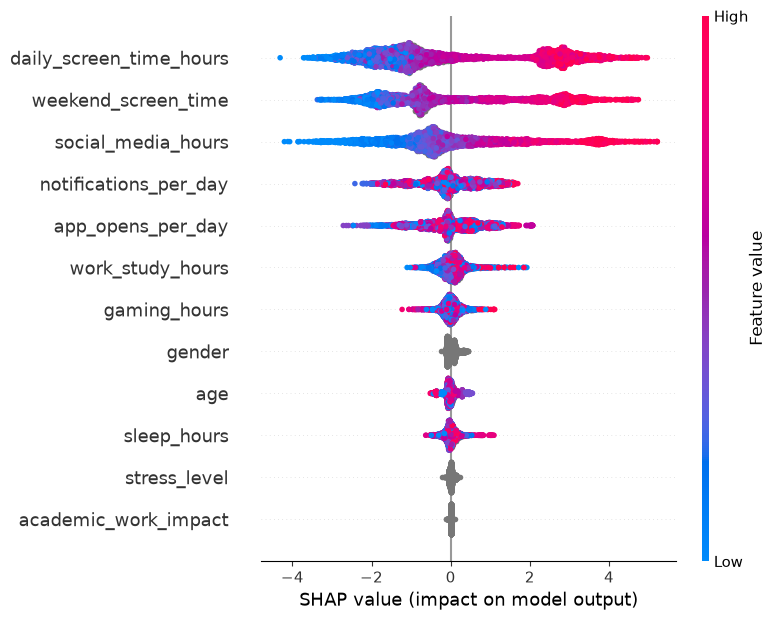

In [12]:
shap.summary_plot(
    shap_values,
    X_shap,
    feature_names=X_shap.columns
)

## 重要度の高い特徴量を個別に見る

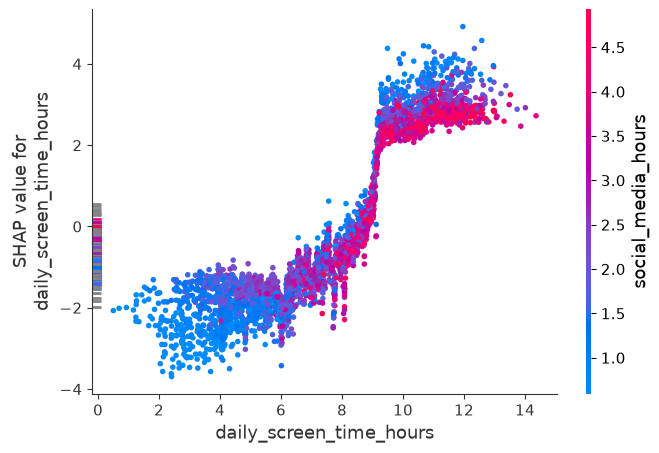

In [13]:
shap.dependence_plot(
    "daily_screen_time_hours",
    shap_values,
    X_shap
)

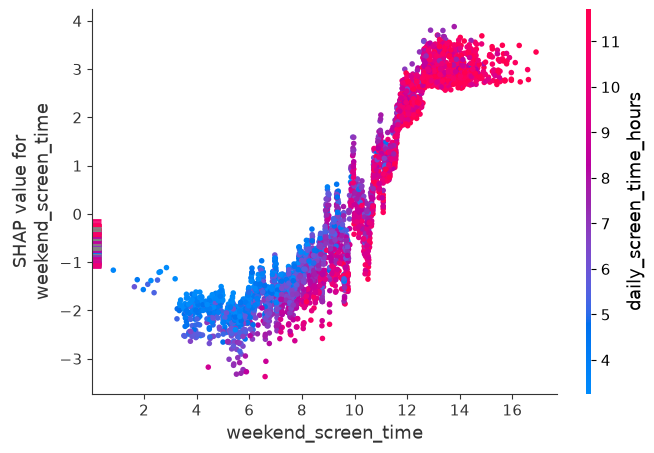

In [14]:
shap.dependence_plot(
    "weekend_screen_time",
    shap_values,
    X_shap
)

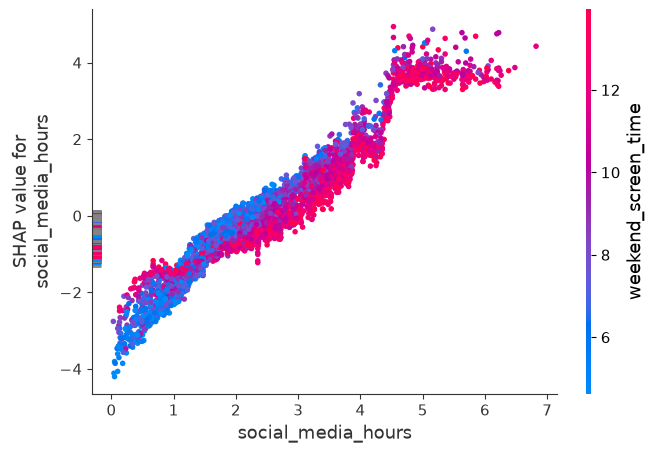

In [15]:
shap.dependence_plot(
    "social_media_hours",
    shap_values,
    X_shap
)

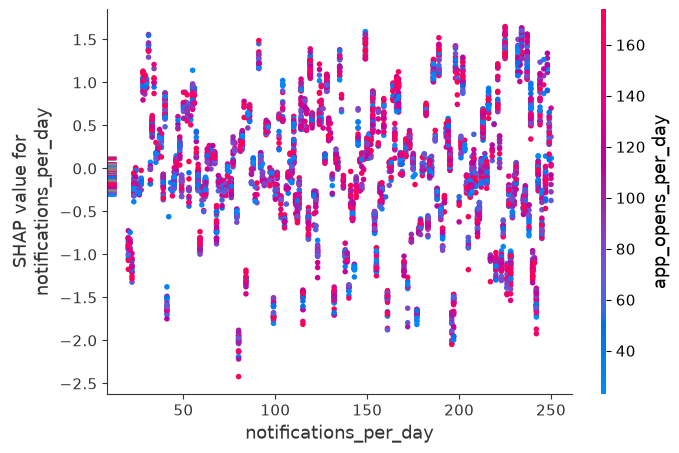

In [16]:
shap.dependence_plot(
    "notifications_per_day",
    shap_values,
    X_shap
)

## 交互作用の確認

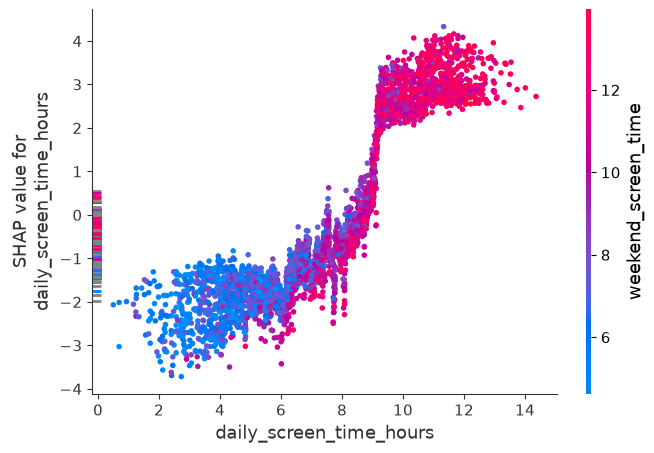

In [17]:
# 横軸：daily screen time、縦軸：そのSHAP効果、色：weekend screen time
shap.dependence_plot(
    "daily_screen_time_hours",
    shap_values,
    X_shap,
    interaction_index="weekend_screen_time"
)

## 特定の一人を説明

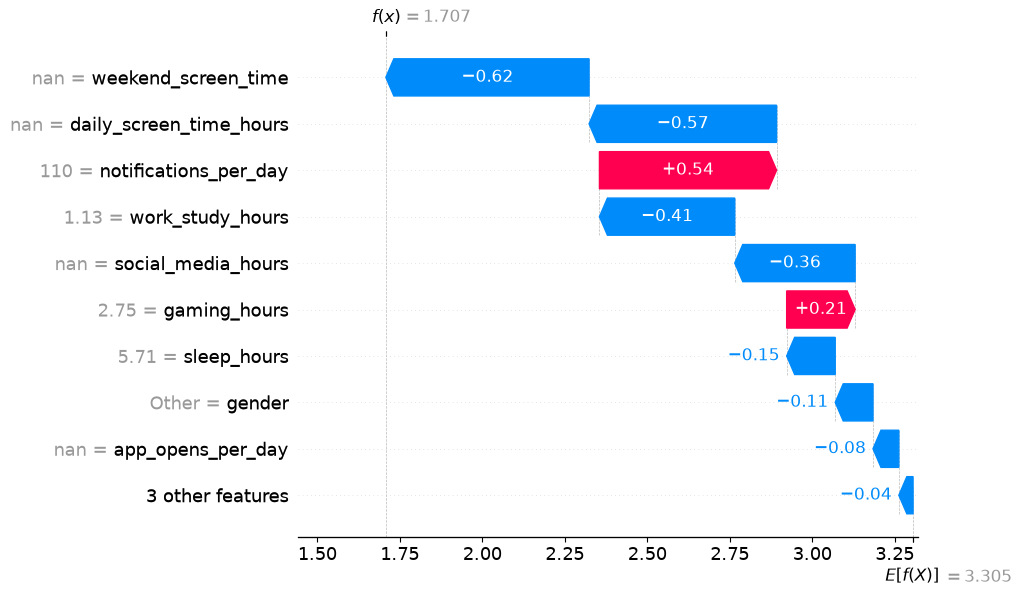

In [18]:
# これによって、この人がなぜこのように分類されたのかがわかる
i = 1

row_explanation = shap.Explanation(
    values=shap_values[i],
    base_values=base_values[i],
    data=X_shap.iloc[i].values,
    feature_names=X_shap.columns.tolist()
)

shap.plots.waterfall(
    row_explanation
)

## 予測確率も併せて見る

In [19]:
i = 1

row = X_shap.iloc[[i]]

prob = final_catboost.predict_proba(
    row
)[0, 1]

print("Predicted probability:", prob)

display(row)

Predicted probability: 0.8465074615514945


,age,daily_screen_time_hours,social_media_hours,gaming_hours,work_study_hours,sleep_hours,notifications_per_day,app_opens_per_day,weekend_screen_time,gender,stress_level,academic_work_impact
354421,34.0,NaN,NaN,2.75,1.13,5.71,110.0,NaN,NaN,Other,Medium,No


## 依存症確率が高い人・低い人を説明

In [20]:
# 高い人
sample_pred = final_catboost.predict_proba(
    X_shap
)[:, 1]

high_idx = np.argmax(sample_pred)

print(
    "Highest probability:",
    sample_pred[high_idx]
)

Highest probability: 0.9999999430836323


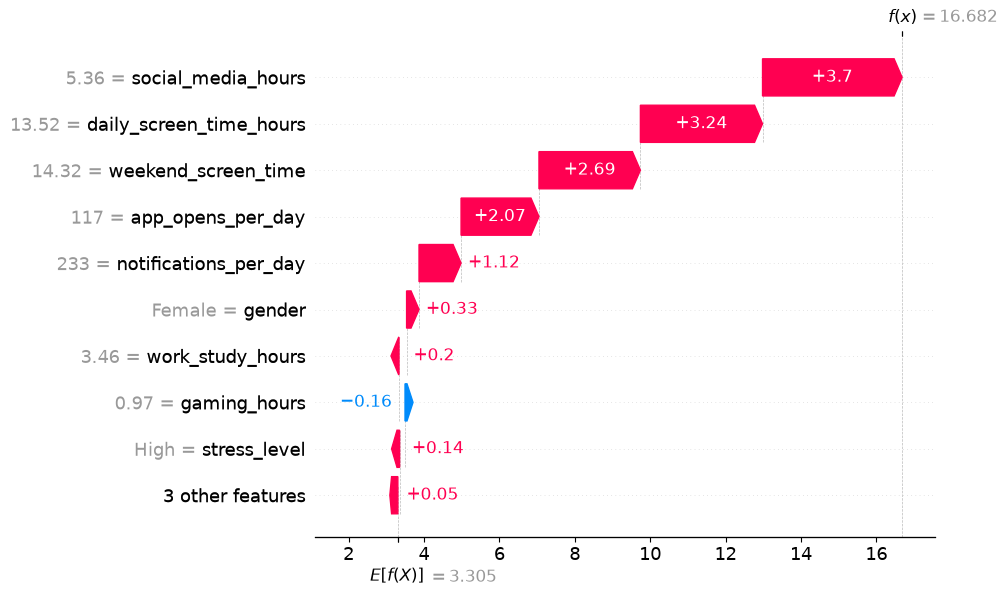

In [21]:
high_explanation = shap.Explanation(
    values=shap_values[high_idx],
    base_values=base_values[high_idx],
    data=X_shap.iloc[high_idx].values,
    feature_names=X_shap.columns.tolist()
)

shap.plots.waterfall(
    high_explanation
)

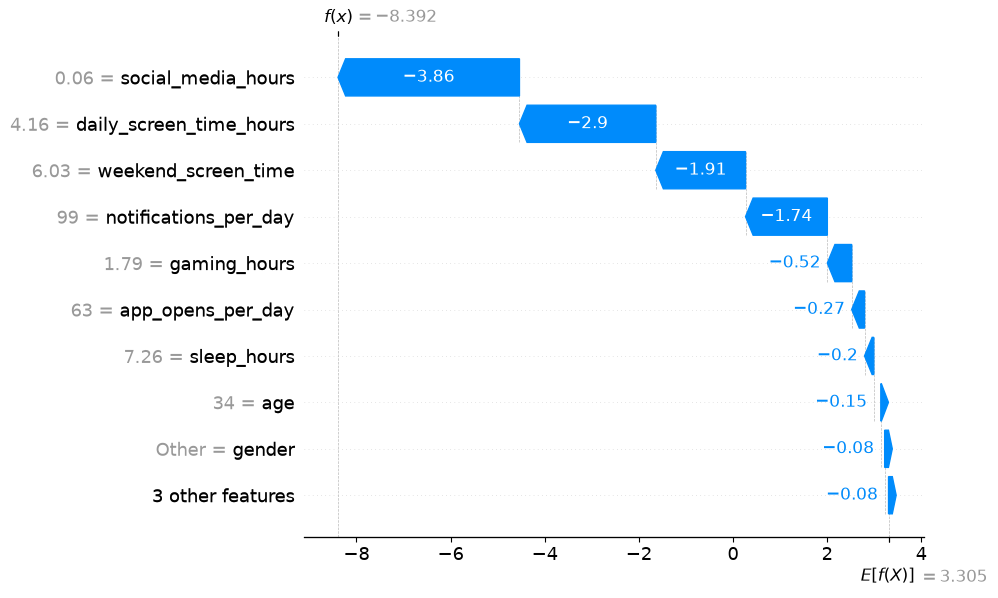

In [22]:
# 低い人
low_idx = np.argmin(sample_pred)

low_explanation = shap.Explanation(
    values=shap_values[low_idx],
    base_values=base_values[low_idx],
    data=X_shap.iloc[low_idx].values,
    feature_names=X_shap.columns.tolist()
)

shap.plots.waterfall(
    low_explanation
)

## catboost の interaction で全組み合わせをランキング
厳密には SHAP interaction values ではないが、まず強いペアを探す際には有用

In [23]:
interaction = final_catboost.get_feature_importance(
    type="Interaction"
)

interaction[:5]

array([[1.        , 6.        , 5.53572837],
       [6.        , 8.        , 5.08703492],
       [1.        , 8.        , 4.97979752],
       [1.        , 7.        , 4.89069988],
       [1.        , 2.        , 4.80330447]])

In [24]:
interaction_df = pd.DataFrame(
    interaction,
    columns=[
        "feature_1_idx",
        "feature_2_idx",
        "interaction_score"
    ]
)

feature_names = X.columns.tolist()

interaction_df["feature_1"] = interaction_df[
    "feature_1_idx"
].astype(int).map(
    lambda i: feature_names[i]
)

interaction_df["feature_2"] = interaction_df[
    "feature_2_idx"
].astype(int).map(
    lambda i: feature_names[i]
)

interaction_df = interaction_df[
    [
        "feature_1",
        "feature_2",
        "interaction_score"
    ]
].sort_values(
    "interaction_score",
    ascending=False
)

display(interaction_df.head(20))

,feature_1,feature_2,interaction_score
0,daily_screen_time_hours,notifications_per_day,5.535728
1,notifications_per_day,weekend_screen_time,5.087035
2,daily_screen_time_hours,weekend_screen_time,4.979798
3,daily_screen_time_hours,app_opens_per_day,4.890700
4,daily_screen_time_hours,social_media_hours,4.803304
5,app_opens_per_day,weekend_screen_time,4.228461
6,daily_screen_time_hours,work_study_hours,3.876275
7,social_media_hours,weekend_screen_time,3.562838
8,daily_screen_time_hours,sleep_hours,3.199930
9,notifications_per_day,app_opens_per_day,3.191011


## SHAP interaction value
１特徴量単位のSHAP値を分解し、main effect、特徴量同士の interaction effect に分解する

In [25]:
# 1000行程度
X_interaction = X.sample(
    n=1000,
    random_state=42
).copy()

In [26]:
# カテゴリ列はこれまで通りの処理
for col in categorical_cols:
    X_interaction[col] = (
        X_interaction[col]
        .fillna("Missing")
        .astype(str)
    )

In [27]:
explainer = shap.TreeExplainer(
    final_catboost
)

interaction_values = (
    explainer.shap_interaction_values(
        X_interaction
    )
)

print(interaction_values.shape)

(1000, 12, 12)


## 全ペアの SHAP interaction をランキング化

In [28]:
n_features = len(X_interaction.columns)

rows = []

for i in range(n_features):
    for j in range(i + 1, n_features):

        mean_abs_interaction = np.abs(
            interaction_values[:, i, j]
        ).mean()

        rows.append({
            "feature_1": X_interaction.columns[i],
            "feature_2": X_interaction.columns[j],
            "mean_abs_interaction":
                mean_abs_interaction
        })

shap_interaction_df = pd.DataFrame(rows)

shap_interaction_df = (
    shap_interaction_df
    .sort_values(
        "mean_abs_interaction",
        ascending=False
    )
    .reset_index(drop=True)
)

display(
    shap_interaction_df.head(20)
)

,feature_1,feature_2,mean_abs_interaction
0,daily_screen_time_hours,weekend_screen_time,0.373160
1,daily_screen_time_hours,social_media_hours,0.292190
2,social_media_hours,weekend_screen_time,0.133157
3,daily_screen_time_hours,work_study_hours,0.124911
4,social_media_hours,work_study_hours,0.093997
5,daily_screen_time_hours,gaming_hours,0.087695
6,social_media_hours,gaming_hours,0.065970
7,work_study_hours,weekend_screen_time,0.064525
8,daily_screen_time_hours,app_opens_per_day,0.055716
9,daily_screen_time_hours,notifications_per_day,0.052018


In [29]:
# sosial_media_hours × weekend_screen_time
shap_interaction_df[
    (
        (
            shap_interaction_df["feature_1"]
            == "social_media_hours"
        )
        &
        (
            shap_interaction_df["feature_2"]
            == "weekend_screen_time"
        )
    )
    |
    (
        (
            shap_interaction_df["feature_1"]
            == "weekend_screen_time"
        )
        &
        (
            shap_interaction_df["feature_2"]
            == "social_media_hours"
        )
    )
]

,feature_1,feature_2,mean_abs_interaction
2,social_media_hours,weekend_screen_time,0.133157


In [30]:
# notification_per_day × app_opens_per_day
shap_interaction_df[
    (
        shap_interaction_df[
            ["feature_1", "feature_2"]
        ]
        .isin([
            "notifications_per_day",
            "app_opens_per_day"
        ])
        .all(axis=1)
    )
]

,feature_1,feature_2,mean_abs_interaction
24,notifications_per_day,app_opens_per_day,0.014342


## 個別の interaction を可視化

In [31]:
i = X_interaction.columns.get_loc(
    "daily_screen_time_hours"
)

j = X_interaction.columns.get_loc(
    "weekend_screen_time"
)

pair_interaction = (
    interaction_values[:, i, j]
)

In [ ]:
# DataFrame
interaction_plot_df = pd.DataFrame({
    "daily_screen_time_hours":
        X_interaction[
            "daily_screen_time_hours"
        ].values,

    "weekend_screen_time":
        X_interaction[
            "weekend_screen_time"
        ].values,

    "interaction_shap":
        pair_interaction
})

display(
    interaction_plot_df.head()
)

,daily_screen_time_hours,weekend_screen_time,interaction_shap
0,NaN,NaN,0.189331
1,NaN,NaN,0.185108
2,2.56,3.75,0.706068
3,5.86,8.72,0.440983
4,7.88,6.61,0.126076


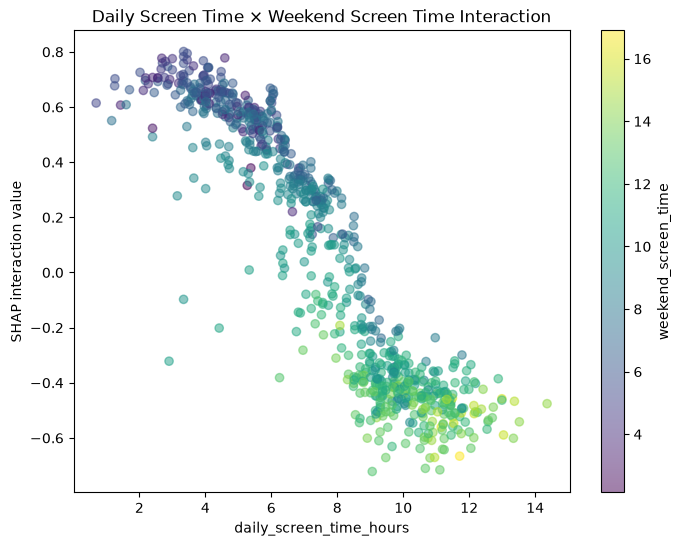

In [34]:
# 散布図
plt.figure(figsize=(8, 6))

plt.scatter(
    interaction_plot_df[
        "daily_screen_time_hours"
    ],
    interaction_plot_df[
        "interaction_shap"
    ],
    c=interaction_plot_df[
        "weekend_screen_time"
    ],
    alpha=0.5
)

plt.xlabel(
    "daily_screen_time_hours"
)
plt.ylabel(
    "SHAP interaction value"
)
plt.title(
    "Daily Screen Time × Weekend Screen Time Interaction"
)

plt.colorbar(
    label="weekend_screen_time"
)

plt.show()